# Counting objects of a given class

I want to count, say, "how many people are in this image" without writing a custom detector. The clean way is a small pretrained YOLO model (`ultralytics`'s `yolov8n.pt` is about 6MB), which knows the 80 COCO classes out of the box.

To get an actual number instead of eyeballing, I score it on real photos with labeled counts: 40 images from the COCO 2017 validation set that contain at least one person. The box labels come from the `detection-datasets/coco` parquet on Hugging Face (only the label columns are read), and the photos are downloaded one by one from the official COCO image host. COCO annotations are CC BY 4.0; the photos are Flickr images under their own Creative Commons licenses.

There's also a contour-based counter, which I test on scikit-image's `coins` photo (a photo of 24 Greek coins from the Brooklyn Museum collection, no known copyright restrictions) where the true count is known.

In [1]:
# !pip install ultralytics -q  # ~6MB model download on first call

In [2]:
import cv2, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

ART = Path("artifacts"); ART.mkdir(exist_ok=True)

try:
    from ultralytics import YOLO
    yolo = YOLO("yolov8n.pt")  # auto-downloads on first run
    HAVE_YOLO = True
except Exception as e:
    HAVE_YOLO = False
    yolo = None
    print("ultralytics not available, falling back to contours.", repr(e)[:120])

## Path A: YOLO

If `ultralytics` is around, this is basically a one-liner. I just count detections whose class name matches whatever I asked for, above a confidence threshold.

In [3]:
def count_with_yolo(img_bgr, target_class="person", conf=0.35):
    if not HAVE_YOLO:
        return None, None
    res = yolo.predict(img_bgr, conf=conf, verbose=False)[0]
    names = res.names  # {class_id: 'name'}
    boxes = res.boxes
    hits = [(int(b.cls.item()), float(b.conf.item()), b.xyxy[0].tolist()) for b in boxes]
    matched = [h for h in hits if names[h[0]] == target_class]
    drawn = img_bgr.copy()
    for cls_id, c, (x1,y1,x2,y2) in matched:
        cv2.rectangle(drawn, (int(x1),int(y1)), (int(x2),int(y2)), (0, 220, 0), 2)
        cv2.putText(drawn, f"{names[cls_id]} {c:.2f}", (int(x1), int(y1)-6),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 220, 0), 1)
    return len(matched), drawn

## Path A on 40 real COCO photos

I take the first 40 validation images that contain a person. COCO marks dense groups of people as a single "crowd" region; this parquet copy doesn't carry that flag, so a few crowded photos may have fewer labeled people than are visible. I count COCO person boxes of any size, and separately the ones at least 32x32 pixels (COCO's "not small" cut), since YOLOv8n struggles with tiny people.

In [4]:
import io, urllib.request
import pandas as pd
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem

fs = HfFileSystem()
val = [f for f in fs.ls("datasets/detection-datasets/coco/data", detail=False) if "/val-" in f][0]
labels = pq.ParquetFile(fs.open(val)).read(columns=["image_id", "objects"]).to_pylist()   # labels only, no pixels

picked = []
for r in labels:
    cats = r["objects"]["category"]
    if 0 in cats:                     # category 0 = person
        picked.append(r)
    if len(picked) == 40:
        break

IMG_DIR = Path("../../data/coco_val_sample"); IMG_DIR.mkdir(parents=True, exist_ok=True)
rows = []
for r in picked:
    path = IMG_DIR / f"{r['image_id']:012d}.jpg"
    if not path.exists():
        urllib.request.urlretrieve(f"http://images.cocodataset.org/val2017/{path.name}", path)
    boxes = [b for b, c in zip(r["objects"]["bbox"], r["objects"]["category"]) if c == 0]   # x1, y1, x2, y2
    gt_all = len(boxes)
    gt_big = sum((b[2] - b[0]) >= 32 and (b[3] - b[1]) >= 32 for b in boxes)
    n, _ = count_with_yolo(cv2.imread(str(path)), target_class="person")
    rows.append({"image_id": r["image_id"], "gt_all": gt_all, "gt_32px": gt_big, "yolo": n})
res = pd.DataFrame(rows)
print(f"images: {len(res)}   labeled people: {res.gt_all.sum()} (>=32px: {res.gt_32px.sum()})   YOLO count: {res.yolo.sum()}")
print(f"MAE vs all people:    {(res.yolo - res.gt_all).abs().mean():.2f} per image   exact: {(res.yolo == res.gt_all).mean():.0%}")
print(f"MAE vs >=32px people: {(res.yolo - res.gt_32px).abs().mean():.2f} per image   exact: {(res.yolo == res.gt_32px).mean():.0%}")

images: 40   labeled people: 200 (>=32px: 136)   YOLO count: 149
MAE vs all people:    1.43 per image   exact: 52%
MAE vs >=32px people: 0.72 per image   exact: 57%


## Path B: contours on a real photo with a known count

contour count on skimage coins: 23  (true: 24)


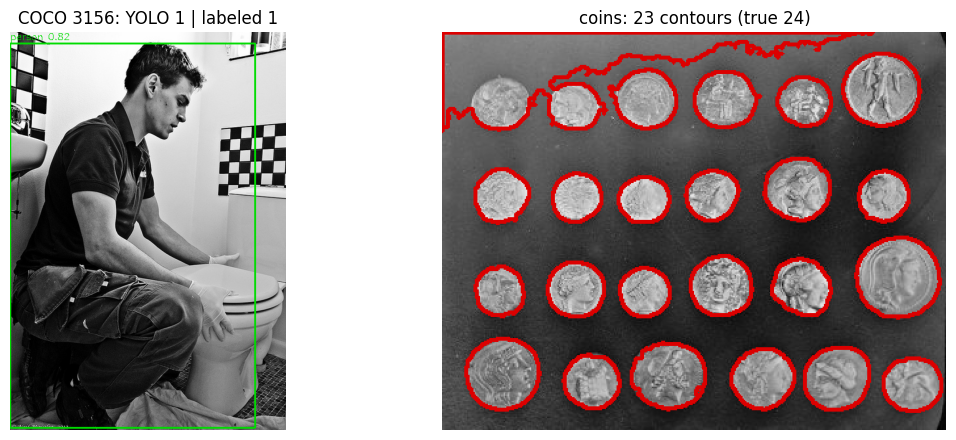

In [5]:
def count_with_contours(img_bgr, min_area=100):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    _, th = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    # close small holes before contouring
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, np.ones((3,3), np.uint8))
    contours, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = [c for c in contours if cv2.contourArea(c) > min_area]
    drawn = img_bgr.copy()
    cv2.drawContours(drawn, contours, -1, (0, 0, 220), 2)
    return len(contours), drawn

from skimage import data
coins = cv2.cvtColor(data.coins(), cv2.COLOR_GRAY2BGR)   # 24 coins on a dark background
n_coins, coins_drawn = count_with_contours(coins)
print(f"contour count on skimage coins: {n_coins}  (true: 24)")

best = res.iloc[(res.gt_all - res.yolo).abs().argsort().iloc[0]]
img = cv2.imread(str(IMG_DIR / f"{int(best.image_id):012d}.jpg"))
_, yolo_drawn = count_with_yolo(img, target_class="person")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].imshow(cv2.cvtColor(yolo_drawn, cv2.COLOR_BGR2RGB)); ax[0].set_title(f"COCO {int(best.image_id)}: YOLO {int(best.yolo)} | labeled {int(best.gt_all)}")
ax[1].imshow(cv2.cvtColor(coins_drawn, cv2.COLOR_BGR2RGB)); ax[1].set_title(f"coins: {n_coins} contours (true 24)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(ART/"object_count.png", dpi=110); plt.show()

## Notes

- On 40 real COCO photos with 200 labeled people, YOLOv8n counts 149. Against every labeled person it's off by 1.4 people per image and exact on 52% of photos. Most of the gap is small people: against the 136 people at least 32x32 pixels it's off by 0.7 per image and exact on 57%. So the nano model mostly undercounts, and mostly on people far from the camera.
- The contour counter gets 23 on the coins photo, where the truth is 24, but the figure shows that's partly luck. The top-left coin merges with the brighter band at the top edge of the photo into one big contour, so one coin is missed and the background is counted once. Uneven lighting is exactly what breaks a single global threshold; an adaptive threshold or a distance-transform + watershed step would be the next thing to try.
- YOLO is the right tool for real scenes. For close-packed objects (items on a shelf, cars in a lot) `ultralytics` does NMS internally, but you can still get double counts or merged boxes, so I'd check counts against labeled images like this before trusting them.